<a href="https://colab.research.google.com/github/dureks23/oss_practice_5/blob/main/oss261104.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. MNIST 데이터셋 로드 및 전처리
# 60,000개의 학습 데이터와 10,000개의 테스트 데이터로 구성되어 있습니다.
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 픽셀 값(0~255)을 0~1 사이의 범위로 정규화(Normalization)합니다.
x_train, x_test = x_train / 255.0, x_test / 255.0

print(f"학습 데이터 형태: {x_train.shape}")
print(f"테스트 데이터 형태: {x_test.shape}")

# 2. 신경망 모델 구축 (Sequential API 사용)
model = models.Sequential([
    # 28x28 2차원 이미지를 1차원(784개)으로 평탄화
    layers.Flatten(input_shape=(28, 28)),

    # 은닉층: 128개의 뉴런, 활성화 함수로 ReLU 사용
    layers.Dense(128, activation='relu'),

    # 드롭아웃(Dropout): 과적합(Overfitting)을 방지하기 위해 20%의 뉴런을 무작위로 끔
    layers.Dropout(0.2),

    # 출력층: 0부터 9까지의 숫자를 분류해야 하므로 10개의 뉴런, 다중 분류에 적합한 softmax 활성화 함수 사용
    layers.Dense(10, activation='softmax')
])

# 3. 모델 컴파일 (손실 함수, 옵티마이저, 평가지표 설정)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 모델 구조 요약 확인
model.summary()

# 4. 모델 학습
# 에포크(Epoch)는 전체 데이터셋을 학습하는 횟수입니다.
print("\n--- 모델 학습 시작 ---")
history = model.fit(x_train, y_train, epochs=5, validation_split=0.2)

# 5. 모델 평가 (테스트 데이터를 이용한 성능 측정)
print("\n--- 모델 평가 ---")
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\n테스트 정확도: {test_acc * 100:.2f}%")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
학습 데이터 형태: (60000, 28, 28)
테스트 데이터 형태: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


--- 모델 학습 시작 ---
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9058 - loss: 0.3247 - val_accuracy: 0.9557 - val_loss: 0.1599
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9533 - loss: 0.1590 - val_accuracy: 0.9640 - val_loss: 0.1210
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9635 - loss: 0.1203 - val_accuracy: 0.9684 - val_loss: 0.1071
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9709 - loss: 0.0961 - val_accuracy: 0.9736 - val_loss: 0.0887
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9743 - loss: 0.0822 - val_accuracy: 0.9755 - val_loss: 0.0807

--- 모델 평가 ---
313/313 - 2s - 6ms/step - accuracy: 0.9753 - loss: 0.0789

테스트 정확도: 97.53%


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 737ms/step


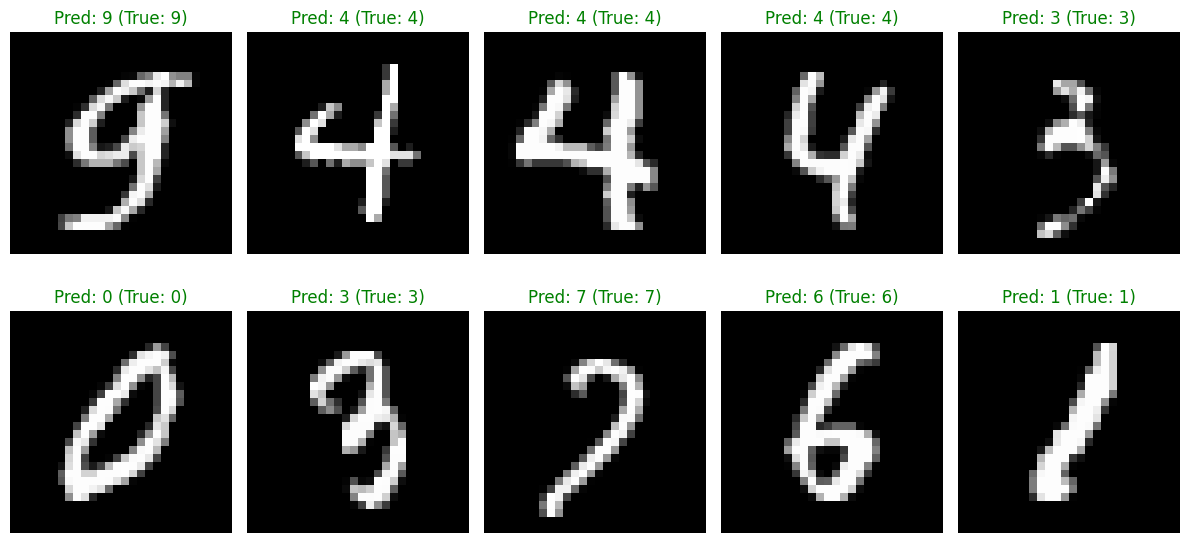

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 테스트 데이터 중 무작위로 10개의 샘플 선택
random_indices = np.random.choice(len(x_test), 10, replace=False)
sample_images = x_test[random_indices]
sample_labels = y_test[random_indices]

# 2. 모델을 통한 예측 수행
predictions = model.predict(sample_images)
predicted_labels = np.argmax(predictions, axis=1)

# 3. 2행 5열의 그리드로 이미지와 예측 결과 시각화
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i], cmap='gray')

    # 예측값과 정답이 일치하면 초록색, 틀리면 빨간색으로 표시
    pred_label = predicted_labels[i]
    true_label = sample_labels[i]

    color = 'green' if pred_label == true_label else 'red'

    plt.title(f"Pred: {pred_label} (True: {true_label})", color=color, fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import tensorflow as tf
from PIL import Image
from io import BytesIO
import base64
import re

from google.colab import output
from IPython.display import display, HTML

# --------------------------------------------------
# 1. 마우스로 그린 이미지 전처리 및 숫자 추론 함수
# --------------------------------------------------

def predict_digit(data_url):

    # Base64 이미지 데이터 추출
    image_data = re.sub(
        '^data:image/.+;base64,',
        '',
        data_url
    )

    image_bytes = base64.b64decode(image_data)

    # 이미지 열기 (흑백 변환)
    img = Image.open(BytesIO(image_bytes)).convert('L')

    # 흰색으로 그려진 숫자의 영역 추출
    img_array = np.array(img)

    # 숫자가 있는 영역 찾기
    coords = np.where(img_array > 20)

    if len(coords[0]) == 0:
        return "숫자를 먼저 그려주세요."

    # 숫자 영역 자르기
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    img = img.crop((x_min, y_min, x_max + 1, y_max + 1))

    # 비율을 유지하면서 최대 20x20 크기로 조정
    img.thumbnail((20, 20), Image.Resampling.LANCZOS)

    # 28x28 검정색 배경 이미지 생성
    new_img = Image.new('L', (28, 28), 0)

    # 숫자를 중앙에 배치
    x_offset = (28 - img.width) // 2
    y_offset = (28 - img.height) // 2

    new_img.paste(img, (x_offset, y_offset))

    # NumPy 배열 변환 및 정규화
    input_data = np.array(new_img, dtype=np.float32)
    input_data = input_data / 255.0

    # 모델 입력 형태: (1, 28, 28)
    input_data = np.expand_dims(input_data, axis=0)

    # 숫자 추론
    predictions = model.predict(input_data, verbose=0)

    predicted_digit = np.argmax(predictions[0])
    confidence = predictions[0][predicted_digit] * 100

    # 상위 3개 예측 결과
    top3 = np.argsort(predictions[0])[-3:][::-1]

    result = f"예측 숫자: {predicted_digit} ({confidence:.2f}%)\n"
    result += "\n".join(
        [f"{digit} : {predictions[0][digit]*100:.2f}%"
         for digit in top3]
    )

    return result


# --------------------------------------------------
# 2. Python 함수와 JavaScript 연결
# --------------------------------------------------

output.register_callback(
    'notebook.predict_digit',
    predict_digit
)


# --------------------------------------------------
# 3. HTML5 Canvas 그림판 구현
# --------------------------------------------------

html_code = """
<div style="text-align:center; font-family:Arial;">

    <h3>MNIST 손글씨 숫자 인식</h3>

    <p>아래 검정색 영역에 0~9 사이의 숫자를 그려보세요.</p>

    <canvas id="drawCanvas"
        width="280"
        height="280"
        style="
            border:3px solid #555;
            background:black;
            cursor:crosshair;
            touch-action:none;
        ">
    </canvas>

    <br><br>

    <button onclick="predictNumber()"
        style="
            padding:10px 25px;
            font-size:16px;
            background:#1976D2;
            color:white;
            border:none;
            border-radius:5px;
            cursor:pointer;
        ">
        숫자 인식하기
    </button>

    <button onclick="clearCanvas()"
        style="
            padding:10px 25px;
            font-size:16px;
            background:#757575;
            color:white;
            border:none;
            border-radius:5px;
            cursor:pointer;
        ">
        지우기
    </button>

    <div id="result"
        style="
            margin-top:20px;
            padding:15px;
            font-size:20px;
            font-weight:bold;
            white-space:pre-line;
            background:#f0f0f0;
            color:#222;
            border-radius:8px;
        ">
        숫자를 그린 후 인식하기 버튼을 누르세요.
    </div>

</div>

<script>

const canvas = document.getElementById('drawCanvas');
const ctx = canvas.getContext('2d');

let drawing = false;

// 초기 캔버스 설정
ctx.fillStyle = 'black';
ctx.fillRect(0, 0, canvas.width, canvas.height);

// 붓 설정
ctx.strokeStyle = 'white';
ctx.lineWidth = 20;
ctx.lineCap = 'round';
ctx.lineJoin = 'round';

// 마우스 및 터치 좌표 계산
function getPosition(e) {
    const rect = canvas.getBoundingClientRect();

    return {
        x: (e.clientX - rect.left) * canvas.width / rect.width,
        y: (e.clientY - rect.top) * canvas.height / rect.height
    };
}

// 그리기 시작
canvas.addEventListener('pointerdown', function(e) {
    drawing = true;

    canvas.setPointerCapture(e.pointerId);

    const pos = getPosition(e);

    ctx.beginPath();
    ctx.moveTo(pos.x, pos.y);
    ctx.lineTo(pos.x, pos.y);
    ctx.stroke();
});

// 마우스 이동
canvas.addEventListener('pointermove', function(e) {
    if (!drawing) return;

    const pos = getPosition(e);

    ctx.lineTo(pos.x, pos.y);
    ctx.stroke();
});

// 그리기 종료
canvas.addEventListener('pointerup', function() {
    drawing = false;
});

canvas.addEventListener('pointercancel', function() {
    drawing = false;
});

// 캔버스 지우기
function clearCanvas() {
    ctx.fillStyle = 'black';
    ctx.fillRect(0, 0, canvas.width, canvas.height);

    document.getElementById('result').innerText =
        '숫자를 그린 후 인식하기 버튼을 누르세요.';
}

// 숫자 추론 요청
async function predictNumber() {

    const resultDiv = document.getElementById('result');

    resultDiv.innerText = '숫자를 분석하고 있습니다...';

    // 캔버스 이미지를 Base64로 변환
    const imageData = canvas.toDataURL('image/png');

    try {

        // Python 함수 호출
        const response = await google.colab.kernel.invokeFunction(
            'notebook.predict_digit',
            [imageData],
            {}
        );

        const result = response.data['text/plain'];

        // Python 문자열 표현의 바깥 따옴표 제거
        resultDiv.innerText = result.replace(/^['"]|['"]$/g, '');

    } catch (error) {

        resultDiv.innerText = '오류 발생: ' + error.message;

    }
}

</script>
"""

display(HTML(html_code))


TensorFlow 버전: 2.21.0
apple 데이터 다운로드 중...
apple: 4000개 로드 완료
bicycle 데이터 다운로드 중...
bicycle: 4000개 로드 완료
cat 데이터 다운로드 중...
cat: 4000개 로드 완료
house 데이터 다운로드 중...
house: 4000개 로드 완료
star 데이터 다운로드 중...
star: 4000개 로드 완료

전체 데이터 형태: (20000, 28, 28, 1)
전체 라벨 형태: (20000,)

학습 데이터: (16000, 28, 28, 1)
테스트 데이터: (4000, 28, 28, 1)


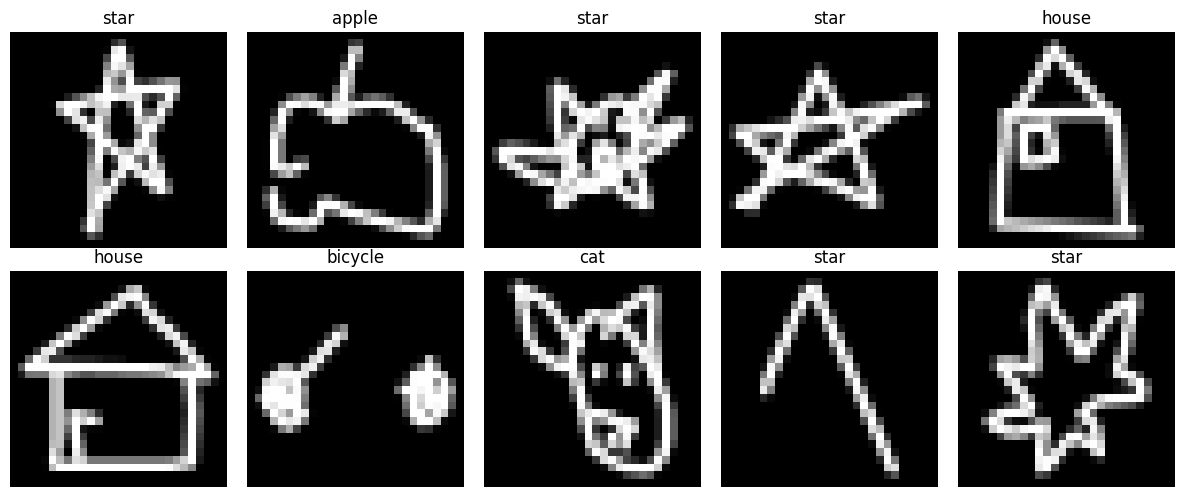

In [4]:
# ============================================
# 1. 라이브러리 불러오기
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

from sklearn.model_selection import train_test_split

print("TensorFlow 버전:", tf.__version__)


# ============================================
# 2. 데이터셋 다운로드
# ============================================

# 분류할 그림 종류
categories = ['apple', 'bicycle', 'cat', 'house', 'star']

# 클래스별 데이터 개수
SAMPLES_PER_CLASS = 4000

# 데이터 저장 폴더
os.makedirs('/content/quickdraw', exist_ok=True)

X_list = []
y_list = []

for label, category in enumerate(categories):

    print(f"{category} 데이터 다운로드 중...")

    url = (
        "https://storage.googleapis.com/"
        "quickdraw_dataset/full/numpy_bitmap/"
        + category + ".npy"
    )

    file_path = f"/content/quickdraw/{category}.npy"

    if not os.path.exists(file_path):
        urllib.request.urlretrieve(url, file_path)

    # Numpy 데이터 로드
    data = np.load(file_path)

    # 클래스별 데이터 일부만 사용
    data = data[:SAMPLES_PER_CLASS]

    X_list.append(data)
    y_list.append(
        np.full(len(data), label)
    )

    print(f"{category}: {len(data)}개 로드 완료")


# ============================================
# 3. 데이터 통합 및 전처리
# ============================================

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# 이미지 형태를 (개수, 28, 28, 1)로 변경
X = X.reshape(-1, 28, 28, 1)

# 픽셀 값 정규화 (0~255 -> 0~1)
X = X.astype('float32') / 255.0

print("\n전체 데이터 형태:", X.shape)
print("전체 라벨 형태:", y.shape)


# ============================================
# 4. 학습 데이터와 테스트 데이터 분리
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)


# ============================================
# 5. 데이터 샘플 시각화
# ============================================

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_train[i].squeeze(),
        cmap='gray'
    )

    plt.title(categories[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 224,389 (876.52 KB)

 Trainable params: 224,389 (876.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8188 - loss: 0.5218 - val_accuracy: 0.9206 - val_loss: 0.2386
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9270 - loss: 0.2238 - val_accuracy: 0.9441 - val_loss: 0.1717
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9452 - loss: 0.1711 - val_accuracy: 0.9456 - val_loss: 0.1617
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9545 - loss: 0.1420 - val_accuracy: 0.9494 - val_loss: 0.1571
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9584 - loss: 0.1248 - val_accuracy: 0.9494 - val_loss: 0.1499
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9629 - loss: 0.1115 - val_accuracy: 0.9447 - val_loss: 0.1520
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9694 - loss: 0.0943 - val_accuracy: 0.9556 - val_loss: 0.1331
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9690 - loss: 0.0905 - val_accuracy: 0

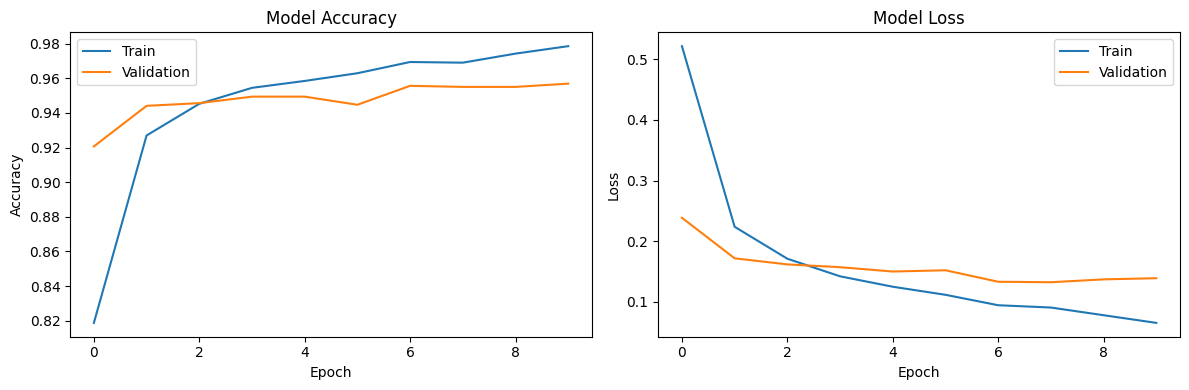

In [5]:
# 1. CNN 모델 구축
# ============================================
# ============================================

from tensorflow.keras import layers, models

model = models.Sequential([

    # 입력층
    layers.Input(shape=(28, 28, 1)),

    # 첫 번째 합성곱층
    layers.Conv2D(
        32,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    # 두 번째 합성곱층
    layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    # 1차원으로 변환
    layers.Flatten(),

    # 완전 연결층
    layers.Dense(128, activation='relu'),

    # 과적합 방지
    layers.Dropout(0.3),

    # 출력층: 5개 클래스
    layers.Dense(
        len(categories),
        activation='softmax'
    )
])


# ============================================
# 2. 모델 컴파일
# ============================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================
# 3. 모델 학습
# ============================================

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


# ============================================
# 4. 모델 평가
# ============================================

test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=2
)

print(f"\n테스트 정확도: {test_acc * 100:.2f}%")


# ============================================
# 5. 학습 결과 그래프
# ============================================

plt.figure(figsize=(12, 4))

# 정확도
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


# 손실
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [6]:
# ============================================
# 1. 이미지 전처리 및 예측 함수
# ============================================

import base64
import re

from PIL import Image
from io import BytesIO

from google.colab import output
from IPython.display import display, HTML


def predict_drawing(data_url):

    # Base64 이미지 데이터 추출
    image_data = re.sub(
        '^data:image/.+;base64,',
        '',
        data_url
    )

    image_bytes = base64.b64decode(image_data)

    # 이미지 열기
    img = Image.open(
        BytesIO(image_bytes)
    ).convert('L')

    # NumPy 배열로 변환
    img_array = np.array(img)

    # 그림이 있는 영역 찾기
    coords = np.where(img_array > 20)

    if len(coords[0]) == 0:
        return "그림을 먼저 그려주세요."

    # 그림 영역 추출
    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    img = img.crop((
        x_min,
        y_min,
        x_max + 1,
        y_max + 1
    ))

    # 가로세로 비율을 유지하면서 20x20으로 축소
    img.thumbnail(
        (20, 20),
        Image.Resampling.LANCZOS
    )

    # 28x28 검정색 배경 생성
    new_img = Image.new(
        'L',
        (28, 28),
        0
    )

    # 그림을 중앙에 배치
    x_offset = (28 - img.width) // 2
    y_offset = (28 - img.height) // 2

    new_img.paste(
        img,
        (x_offset, y_offset)
    )

    # 정규화
    input_data = np.array(
        new_img,
        dtype=np.float32
    ) / 255.0

    # 모델 입력 형태 변경
    input_data = input_data.reshape(
        1, 28, 28, 1
    )

    # AI 예측
    predictions = model.predict(
        input_data,
        verbose=0
    )[0]

    # 가장 높은 확률의 클래스
    predicted_index = np.argmax(predictions)

    predicted_class = categories[predicted_index]

    confidence = predictions[predicted_index] * 100

    # 상위 3개 예측 결과
    top3 = np.argsort(predictions)[-3:][::-1]

    result = f"AI의 예측: {predicted_class.upper()} ({confidence:.2f}%)"

    for index in top3:
        result += (
            f" | {categories[index]}: "
            f"{predictions[index] * 100:.2f}%"
        )

    return result


# ============================================
# 2. Python 함수 등록
# ============================================

output.register_callback(
    'notebook.predict_drawing',
    predict_drawing
)


# ============================================
# 3. HTML5 Canvas 그림판
# ============================================

html_code = """

<div style="
    max-width:600px;
    margin:auto;
    text-align:center;
    font-family:Arial,sans-serif;
">

    <h2>🎨 AI 그림 맞히기 게임</h2>

    <p>
        사과, 자전거, 고양이, 집, 별 중 하나를 그려보세요!
    </p>

    <p style="color:#777;font-size:14px;">
        마우스로 그림을 그린 후 AI에게 맞혀보세요.
    </p>

    <!-- 그림판 -->
    <canvas id="drawCanvas"
        width="280"
        height="280"
        style="
            border:3px solid #555;
            background:black;
            cursor:crosshair;
            touch-action:none;
            border-radius:8px;
        ">
    </canvas>

    <br><br>

    <!-- 버튼 -->
    <button onclick="predictDrawing()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#1976D2;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        🤖 AI에게 물어보기
    </button>

    <button onclick="clearCanvas()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#757575;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        지우기
    </button>

    <!-- 결과 -->
    <div id="result"
        style="
            margin-top:20px;
            padding:20px;
            background:#f1f3f5;
            color:#222;
            border-radius:10px;
            font-size:17px;
            line-height:1.8;
            white-space:pre-line;
        ">
        그림을 그린 후 AI에게 물어보세요!
    </div>

</div>


<script>

// ========================================
// 1. Canvas 설정
// ========================================

const canvas = document.getElementById('drawCanvas');

const ctx = canvas.getContext('2d');

// 검정색 배경
ctx.fillStyle = 'black';

ctx.fillRect(
    0, 0,
    canvas.width,
    canvas.height
);

// 흰색 붓
ctx.strokeStyle = 'white';

ctx.lineWidth = 18;

ctx.lineCap = 'round';

ctx.lineJoin = 'round';

let drawing = false;


// ========================================
// 2. 마우스 좌표 계산
// ========================================

function getPosition(e) {

    const rect = canvas.getBoundingClientRect();

    return {
        x: (e.clientX - rect.left)
            * canvas.width / rect.width,

        y: (e.clientY - rect.top)
            * canvas.height / rect.height
    };
}


// ========================================
// 3. 그림 그리기
// ========================================

// 마우스 클릭
canvas.addEventListener('pointerdown', function(e) {

    drawing = true;

    canvas.setPointerCapture(e.pointerId);

    const pos = getPosition(e);

    ctx.beginPath();

    ctx.moveTo(pos.x, pos.y);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


// 마우스 이동
canvas.addEventListener('pointermove', function(e) {

    if (!drawing) return;

    const pos = getPosition(e);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


// 마우스 버튼 해제
canvas.addEventListener('pointerup', function() {

    drawing = false;

});

canvas.addEventListener('pointercancel', function() {

    drawing = false;

});


// ========================================
// 4. 그림판 초기화
// ========================================

function clearCanvas() {

    ctx.fillStyle = 'black';

    ctx.fillRect(
        0, 0,
        canvas.width,
        canvas.height
    );

    document.getElementById('result').innerText =
        '그림을 그린 후 AI에게 물어보세요!';

}


// ========================================
// 5. AI 추론 요청
// ========================================

async function predictDrawing() {

    const resultDiv = document.getElementById('result');

    resultDiv.innerText = '🤖 AI가 그림을 분석하고 있습니다...';

    // Canvas 이미지를 Base64로 변환
    const imageData = canvas.toDataURL('image/png');

    try {

        // Python 함수 호출
        const response = await google.colab.kernel.invokeFunction(
            'notebook.predict_drawing',
            [imageData],
            {}
        );

        // Python 결과 가져오기
        const result = response.data['text/plain'];

        // 결과 표시
        resultDiv.innerText = String(result).replace(/^['"]|['"]$/g, '');

    }

    catch(error) {

        resultDiv.innerText =
            '오류가 발생했습니다: ' + error.message;

    }

}

</script>

"""

display(HTML(html_code))


TensorFlow 버전: 2.21.0


Saving flower_dataset.zip to flower_dataset.zip
압축 해제 완료!
데이터 경로: /content/flower_dataset/flower_dataset
morning_glory: 9장
cactus: 9장
rose: 9장
Found 27 files belonging to 3 classes.
Using 22 files for training.
Found 27 files belonging to 3 classes.
Using 5 files for validation.


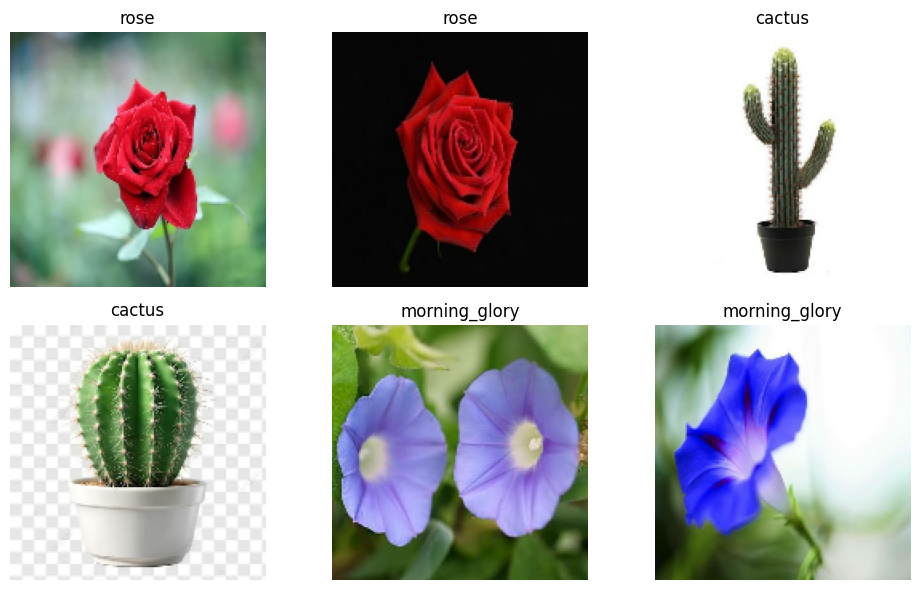

데이터 전처리 완료!


In [10]:

# ============================================
# 1. 라이브러리 불러오기
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from google.colab import files

print("TensorFlow 버전:", tf.__version__)


# ============================================
# 2. ZIP 파일 업로드 및 압축 해제
# ============================================

uploaded = files.upload()

zip_path = next(iter(uploaded.keys()))

extract_path = '/content/flower_dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("압축 해제 완료!")


# ============================================
# 3. 분류할 식물 종류 설정
# ============================================

categories = [
    'morning_glory',
    'cactus',
    'rose'
]

dataset_path = None

for root, dirs, files_list in os.walk(extract_path):
    if all(category in dirs for category in categories):
        dataset_path = root
        break

if dataset_path is None:
    raise ValueError("데이터셋 폴더 구조를 확인해주세요.")

print("데이터 경로:", dataset_path)


# ============================================
# 4. 이미지 개수 확인
# ============================================

for category in categories:

    folder = os.path.join(dataset_path, category)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
        )
    ])

    print(f"{category}: {count}장")

    if count < 2:
        raise ValueError(
            f"{category} 사진이 너무 적습니다."
        )


# ============================================
# 5. 이미지 데이터 불러오기
# ============================================

IMG_SIZE = (160, 160)
BATCH_SIZE = 6
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='int',
    class_names=categories,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='training',
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels='inferred',
    label_mode='int',
    class_names=categories,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset='validation',
    seed=SEED
)


# ============================================
# 6. 이미지 샘플 확인
# ============================================

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):

    for i in range(len(images)):

        plt.subplot(2, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype('uint8')
        )

        plt.title(
            categories[labels[i].numpy()]
        )

        plt.axis('off')

plt.tight_layout()
plt.show()


# ============================================
# 7. 데이터 성능 최적화
# ============================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

print("데이터 전처리 완료!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 652ms/step - accuracy: 0.3182 - loss: 1.4099 - val_accuracy: 0.6000 - val_loss: 0.8991
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3182 - loss: 1.3317 - val_accuracy: 0.6000 - val_loss: 0.8642
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4545 - loss: 1.3659 - val_accuracy: 0.8000 - val_loss: 0.8308
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.3636 - loss: 1.3854 - val_accuracy: 0.8000 - val_loss: 0.8001
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5455 - loss: 1.0936 - val_accuracy: 0.8000 - val_loss: 0.7699
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4091 - loss: 0.9806 - val_accuracy: 0.8000 - val_loss: 0.7410
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5000 - loss: 1.1949 - val_accuracy: 0.8000 - val_loss: 0.7136
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.4545 - loss: 1.2498 - val_accuracy: 1.0000 - val_loss: 0.690

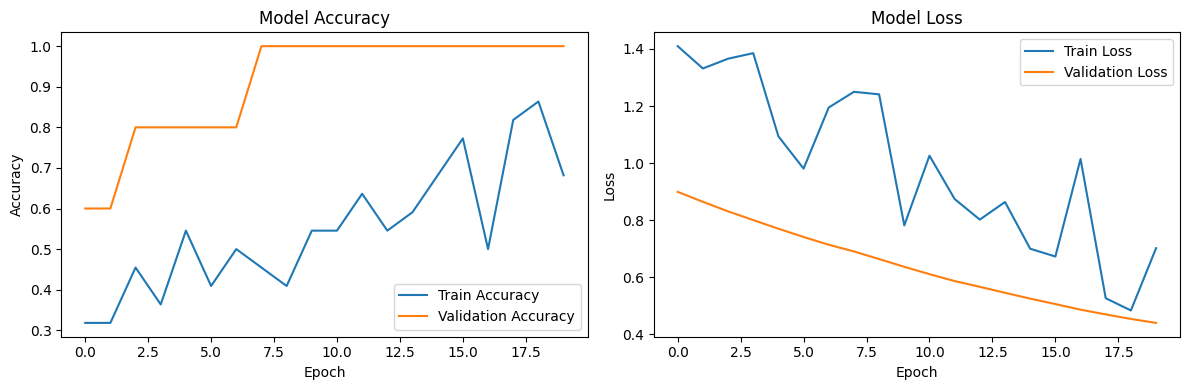

모델 저장 완료!


In [11]:

# ============================================
# 1. 라이브러리 불러오기
# ============================================

from tensorflow.keras import layers, models


# ============================================
# 2. 사전 학습된 MobileNetV2 불러오기
# ============================================

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)

# 기존 학습 가중치 고정
base_model.trainable = False


# ============================================
# 3. 데이터 증강
# ============================================

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


# ============================================
# 4. 모델 구축
# ============================================

model = models.Sequential([

    layers.Input(shape=(160, 160, 3)),

    # 데이터 증강
    data_augmentation,

    # MobileNetV2 입력 전처리
    layers.Rescaling(
        scale=1./127.5,
        offset=-1
    ),

    # 이미지 특징 추출
    base_model,

    # 특징 데이터 평균화
    layers.GlobalAveragePooling2D(),

    # 과적합 방지
    layers.Dropout(0.3),

    # 3개 식물 분류
    layers.Dense(
        3,
        activation='softmax'
    )
])


# ============================================
# 5. 모델 컴파일
# ============================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================
# 6. 모델 학습
# ============================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[early_stop]
)


# ============================================
# 7. 모델 평가
# ============================================

test_loss, test_acc = model.evaluate(
    val_ds,
    verbose=2
)

print(
    f"검증 정확도: {test_acc * 100:.2f}%"
)


# ============================================
# 8. 학습 결과 그래프
# ============================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history['loss'],
    label='Train Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ============================================
# 9. 모델 저장
# ============================================

model.save('/content/flower_classifier.keras')

print("모델 저장 완료!")


Saving rose.jpg to rose.jpg
🌱 AI 식물 분류 결과
예측 결과: cactus
예측 확률: 48.19%

[전체 예측 확률]
cactus: 48.19%
rose: 29.04%
morning_glory: 22.77%


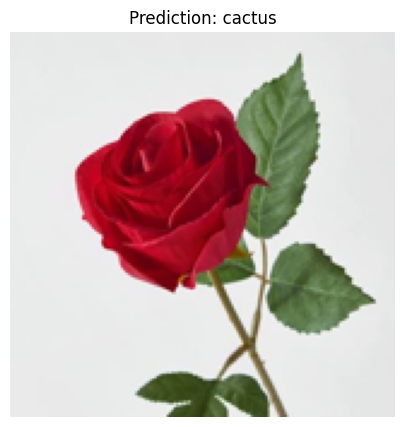

In [14]:

# ============================================
# 1. 필요한 라이브러리
# ============================================

from PIL import Image
from google.colab import files


# ============================================
# 2. 식물 예측 함수
# ============================================

def predict_plant(image_path):

    # 이미지 불러오기
    img = Image.open(image_path).convert('RGB')

    # 이미지 크기 변경
    img = img.resize((160, 160))

    # 배열로 변환
    input_data = np.array(
        img,
        dtype=np.float32
    )

    # 모델 입력 형태로 변환
    input_data = np.expand_dims(
        input_data,
        axis=0
    )

    # AI 예측
    predictions = model.predict(
        input_data,
        verbose=0
    )[0]

    # 가장 높은 확률의 클래스
    predicted_index = np.argmax(predictions)

    predicted_class = categories[predicted_index]

    confidence = predictions[predicted_index] * 100

    # 결과 출력
    print("=" * 40)
    print("🌱 AI 식물 분류 결과")
    print("=" * 40)

    print(f"예측 결과: {predicted_class}")
    print(f"예측 확률: {confidence:.2f}%")

    print("\n[전체 예측 확률]")

    top3 = np.argsort(predictions)[::-1]

    for index in top3:

        print(
            f"{categories[index]}: "
            f"{predictions[index] * 100:.2f}%"
        )

    # 이미지 출력
    plt.figure(figsize=(5, 5))

    plt.imshow(img)

    plt.title(
        f"Prediction: {predicted_class}"
    )

    plt.axis('off')

    plt.show()


# ============================================
# 3. 새로운 사진 업로드
# ============================================

uploaded = files.upload()

for filename in uploaded.keys():

    predict_plant(filename)
